# Explainable and Robust Diamond Price Prediction Using Machine Learning with What-If Analysis

## Project Overview

This project develops a machine-learning-based framework for diamond price prediction using a richer set of diamond characteristics. The study evaluates feature enrichment, compares regression models, performs cross-validation, explains predictions using SHAP, and demonstrates controlled What-If analysis.


## Research Objective

The primary objective of this study is to investigate how the inclusion of richer diamond characteristics affects the performance of machine-learning-based diamond price prediction.

The study also evaluates multiple regression models, validates their performance using cross-validation, explains model predictions using SHAP, and demonstrates controlled What-If analysis for individual diamond attributes.

## Research Questions

1. How much does prediction performance improve when moving from traditional 4C characteristics to richer diamond features?

2. What is the contribution of dimensions and physical/quality characteristics to diamond price prediction?

3. How do Random Forest, Gradient Boosting, and Extra Trees compare when using the complete feature set?

4. How consistent is model performance across different cross-validation folds?

5. Which features contribute most strongly to individual model predictions?

6. How can What-If analysis be used to examine changes in model-predicted diamond prices under controlled feature changes?

## Literature-Based Research Gap

A review of previous diamond price prediction studies identified several recurring limitations and opportunities:

1. **Limited feature coverage:** Several studies primarily rely on the traditional 4C characteristics or a relatively small set of diamond attributes.

2. **Feature engineering and enrichment:** Previous research indicates that additional physical measurements and engineered characteristics can improve prediction performance, but their incremental contribution requires systematic evaluation.

3. **Generalization concerns:** Several studies rely on a single dataset or marketplace source, which limits evidence about how well the models generalize beyond the evaluated data.

4. **Model-comparison focus:** Many studies primarily compare regression algorithms and select a model based on prediction metrics, with less emphasis on controlled feature-ablation experiments.

5. **Interpretability:** Prediction accuracy alone does not explain why an individual diamond receives a particular predicted price.

6. **Practical interaction:** There is an opportunity to complement prediction and feature importance with controlled What-If analysis, allowing users to examine how hypothetical changes in selected attributes affect model-predicted prices.

### Research Response

This study addresses these gaps through a controlled experimental framework that combines:

- Feature-set ablation from 4C features to a richer 17-feature representation.
- Comparison of Random Forest, Gradient Boosting, and Extra Trees.
- Five-fold cross-validation for robustness assessment.
- SHAP-based model explanation.
- Controlled What-If analysis for individual predictions.

## Dataset Description

The original diamond marketplace dataset contained 6,485 records and 18 attributes. After removing 3 exact duplicate records during data cleaning, the final dataset used for modeling contains 6,482 records and 18 attributes.

### Dataset Features

The dataset contains the following attributes:

- Shape
- Cut
- Color
- Clarity
- Carat Weight
- Length/Width Ratio
- Depth %
- Table %
- Polish
- Symmetry
- Girdle
- Culet
- Length
- Width
- Height
- Price
- Type
- Fluorescence

### Target Variable

The target variable is:

**Price** — the observed diamond price.

### Feature Groups

For the feature-ablation experiments, the attributes are organized into progressively richer feature groups:

1. **4C Features**
   - Carat Weight
   - Cut
   - Color
   - Clarity

2. **4C + Dimensions**
   - 4C features
   - Length
   - Width
   - Height

3. **4C + Dimensions + Physical/Quality**
   - Previous features
   - Length/Width Ratio
   - Depth %
   - Table %
   - Polish
   - Symmetry

4. **All 17 Features**
   - All available predictor attributes excluding the target variable, Price.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/diamonds (cleaned).csv")

df.head()

,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Price,Type,Fluorescence
0,Cushion Modified,Ideal,F,VVS2,1.84,1.02,65.8,59.0,Excellent,Very Good,Medium to Thick,NaN,7.09,6.95,4.57,2640,GIA Lab-Grown,NaN
1,Pear,NaN,E,VS1,1.20,1.65,62.5,58.0,Very Good,Very Good,Medium to Thick,NaN,9.64,5.86,3.66,1070,GIA Lab-Grown,NaN
2,Oval,NaN,E,VS1,1.19,1.41,63.1,63.0,Very Good,Very Good,Medium to Thick,NaN,8.44,6.00,3.79,1070,GIA Lab-Grown,NaN
3,Heart,NaN,D,IF,1.00,1.18,61.7,58.0,Excellent,Excellent,Slightly Thick to Very Thick,NaN,5.85,6.89,4.25,7110,GIA,Faint
4,Radiant,NaN,H,VS1,1.01,1.35,69.4,66.0,Excellent,Very Good,Thick,NaN,6.80,5.05,3.50,3050,GIA,NaN


In [3]:
# Step 124: Dataset Overview

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (6485, 18)

Column Names:
['Shape', 'Cut', 'Color', 'Clarity', 'Carat Weight', 'Length/Width Ratio', 'Depth %', 'Table %', 'Polish', 'Symmetry', 'Girdle', 'Culet', 'Length', 'Width', 'Height', 'Price', 'Type', 'Fluorescence']

Data Types:
Shape                     str
Cut                       str
Color                     str
Clarity                   str
Carat Weight          float64
Length/Width Ratio    float64
Depth %               float64
Table %               float64
Polish                    str
Symmetry                  str
Girdle                    str
Culet                     str
Length                float64
Width                 float64
Height                float64
Price                   int64
Type                      str
Fluorescence              str
dtype: object

First 5 Rows:


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Price,Type,Fluorescence
0,Cushion Modified,Ideal,F,VVS2,1.84,1.02,65.8,59.0,Excellent,Very Good,Medium to Thick,NaN,7.09,6.95,4.57,2640,GIA Lab-Grown,NaN
1,Pear,NaN,E,VS1,1.20,1.65,62.5,58.0,Very Good,Very Good,Medium to Thick,NaN,9.64,5.86,3.66,1070,GIA Lab-Grown,NaN
2,Oval,NaN,E,VS1,1.19,1.41,63.1,63.0,Very Good,Very Good,Medium to Thick,NaN,8.44,6.00,3.79,1070,GIA Lab-Grown,NaN
3,Heart,NaN,D,IF,1.00,1.18,61.7,58.0,Excellent,Excellent,Slightly Thick to Very Thick,NaN,5.85,6.89,4.25,7110,GIA,Faint
4,Radiant,NaN,H,VS1,1.01,1.35,69.4,66.0,Excellent,Very Good,Thick,NaN,6.80,5.05,3.50,3050,GIA,NaN


In [4]:
# Step 125: Missing Value Analysis

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    "Missing Count",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
Fluorescence,5264,81.171935
Culet,4594,70.840401
Cut,4303,66.353123
Girdle,22,0.339244
Symmetry,20,0.308404
Width,20,0.308404
Length,20,0.308404
Polish,20,0.308404
Height,20,0.308404
Table %,17,0.262143


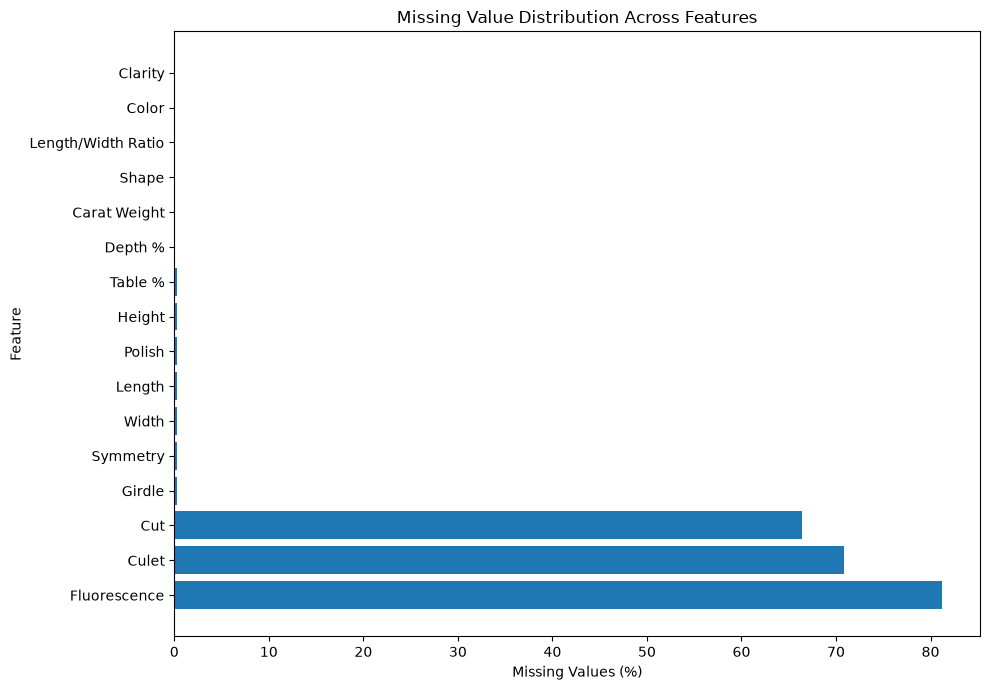

In [5]:
# Step 126: Missing Value Visualization

plt.figure(figsize=(10, 7))

plt.barh(
    missing_summary.index,
    missing_summary["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing Value Distribution Across Features")

plt.tight_layout()
plt.show()

In [6]:
# Step 127: Missingness by Diamond Type

missing_by_type = df.groupby("Type")[[
    "Cut",
    "Culet",
    "Fluorescence"
]].apply(lambda x: x.isna().mean() * 100)

missing_by_type

,Cut,Culet,Fluorescence
Type,,,
GIA,71.058122,99.105812,63.606557
GIA Lab-Grown,43.859649,100.000000,100.000000
IGI Lab-Grown,72.974414,0.799574,100.000000


## Missingness Interpretation

The missing-value analysis shows that missingness is strongly associated with the diamond Type for several categorical attributes.

Cut has substantial missingness across all three Type groups, while Culet is almost entirely missing for GIA and GIA Lab-Grown diamonds but is largely available for IGI Lab-Grown diamonds. Fluorescence is completely missing for the lab-grown groups and partially missing for GIA diamonds.

Therefore, these variables are not removed solely because of their high overall missing percentage. Instead, missing categorical values are retained through an "Unknown" category during preprocessing. This preserves the information that a value was not recorded while avoiding arbitrary mode imputation.

In [7]:
# Duplicate Record Check and Removal

duplicate_count = df.duplicated().sum()

print("Duplicate records before removal:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate records after removal:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Duplicate records before removal: 3
Duplicate records after removal: 0
Final dataset shape: (6482, 18)


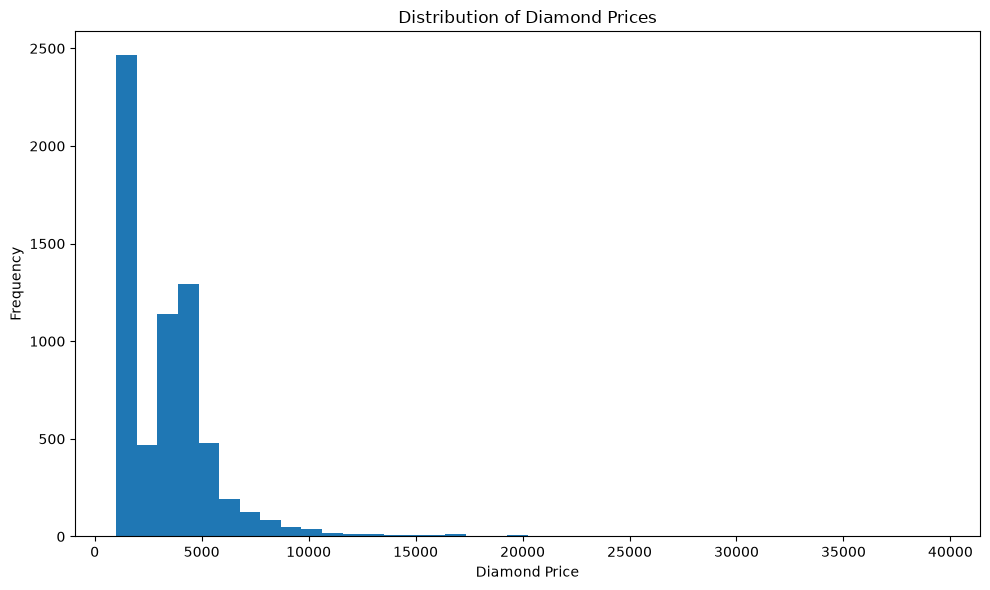

In [8]:
# Step 131: Price Distribution

plt.figure(figsize=(10, 6))

plt.hist(
    df["Price"],
    bins=40
)

plt.xlabel("Diamond Price")
plt.ylabel("Frequency")
plt.title("Distribution of Diamond Prices")

plt.tight_layout()
plt.show()

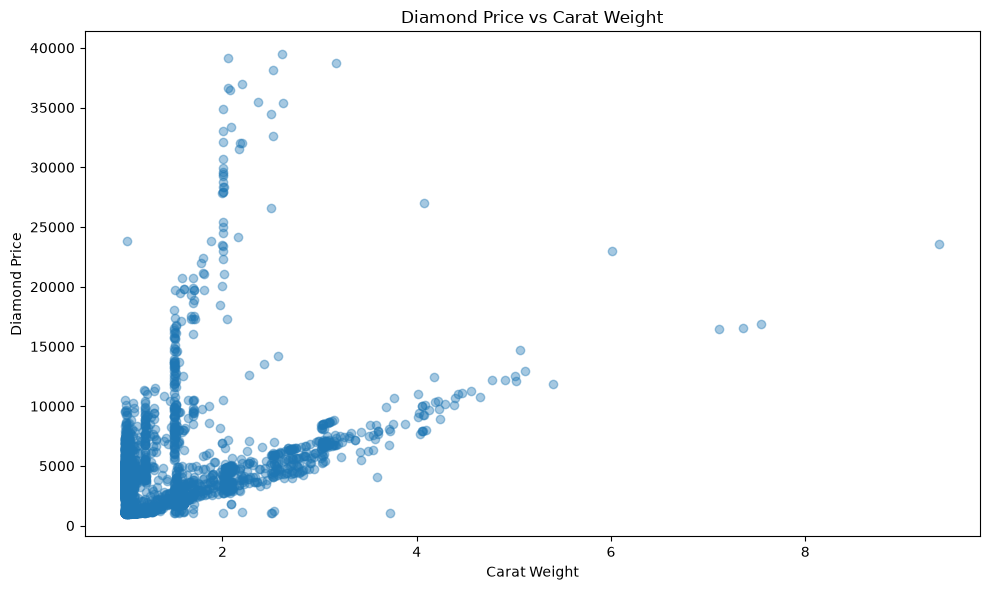

In [9]:
# Step 132: Price vs Carat Weight

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Carat Weight"],
    df["Price"],
    alpha=0.4
)

plt.xlabel("Carat Weight")
plt.ylabel("Diamond Price")
plt.title("Diamond Price vs Carat Weight")

plt.tight_layout()
plt.show()

In [10]:
# Step 133: Numerical Correlation with Price

correlation_with_price = (
    df.select_dtypes(include=np.number)
      .corr()["Price"]
      .sort_values(ascending=False)
)

correlation_with_price

Price                 1.000000
Carat Weight          0.368770
Length                0.314793
Width                 0.261288
Height                0.217991
Length/Width Ratio    0.151801
Table %              -0.098497
Depth %              -0.183515
Name: Price, dtype: float64

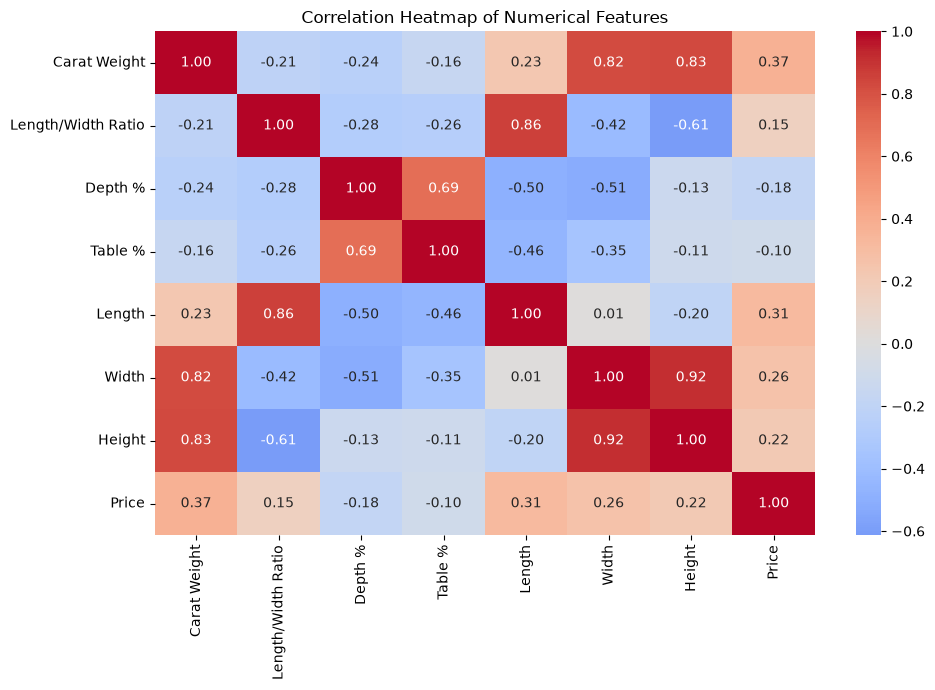

In [11]:
# Step 134: Numerical Feature Correlation Heatmap

numerical_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

In [12]:
# Step 135: Price Distribution by Diamond Type

type_summary = df.groupby("Type")["Price"].agg(
    ["count", "mean", "median"]
).sort_values(
    "mean",
    ascending=False
)

type_summary

,count,mean,median
Type,,,
GIA,3355,4890.969598,4090.0
GIA Lab-Grown,1253,2702.913009,1790.0
IGI Lab-Grown,1874,1644.610459,1150.0


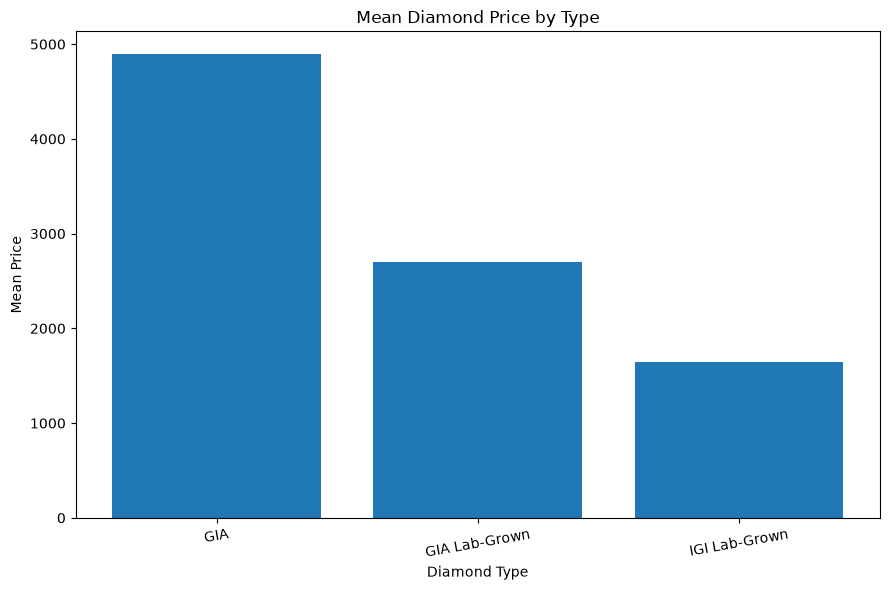

In [13]:
# Step 136: Mean Price by Diamond Type

plt.figure(figsize=(9, 6))

plt.bar(
    type_summary.index,
    type_summary["mean"]
)

plt.xlabel("Diamond Type")
plt.ylabel("Mean Price")
plt.title("Mean Diamond Price by Type")

plt.xticks(rotation=10)
plt.tight_layout()

plt.show()

In [14]:
# Step 137: Categorical Feature Distribution

categorical_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Polish",
    "Symmetry",
    "Type"
]

for feature in categorical_features:
    print(f"\n{feature} Value Counts:")
    print(df[feature].value_counts(dropna=False))


Shape Value Counts:
Shape
Round               886
Pear                840
Marquise            835
Princess            833
Oval                828
Heart               826
Radiant             801
Cushion Modified    365
Emerald             137
Cushion              91
Square Radiant       35
NaN                   5
Name: count, dtype: int64

Cut Value Counts:
Cut
NaN          4302
Ideal        1308
Excellent     606
Very Good     258
Astor           8
Name: count, dtype: int64

Color Value Counts:
Color
E      1883
D      1770
H      1117
F       969
G       738
NaN       5
Name: count, dtype: int64

Clarity Value Counts:
Clarity
VS1     3335
VS2     1433
VVS2    1060
VVS1     480
IF       163
FL         6
NaN        5
Name: count, dtype: int64

Polish Value Counts:
Polish
Excellent    5936
Very Good     492
Good           34
NaN            20
Name: count, dtype: int64

Symmetry Value Counts:
Symmetry
Excellent    4549
Very Good    1789
Good          124
NaN            20
Name: count, dt

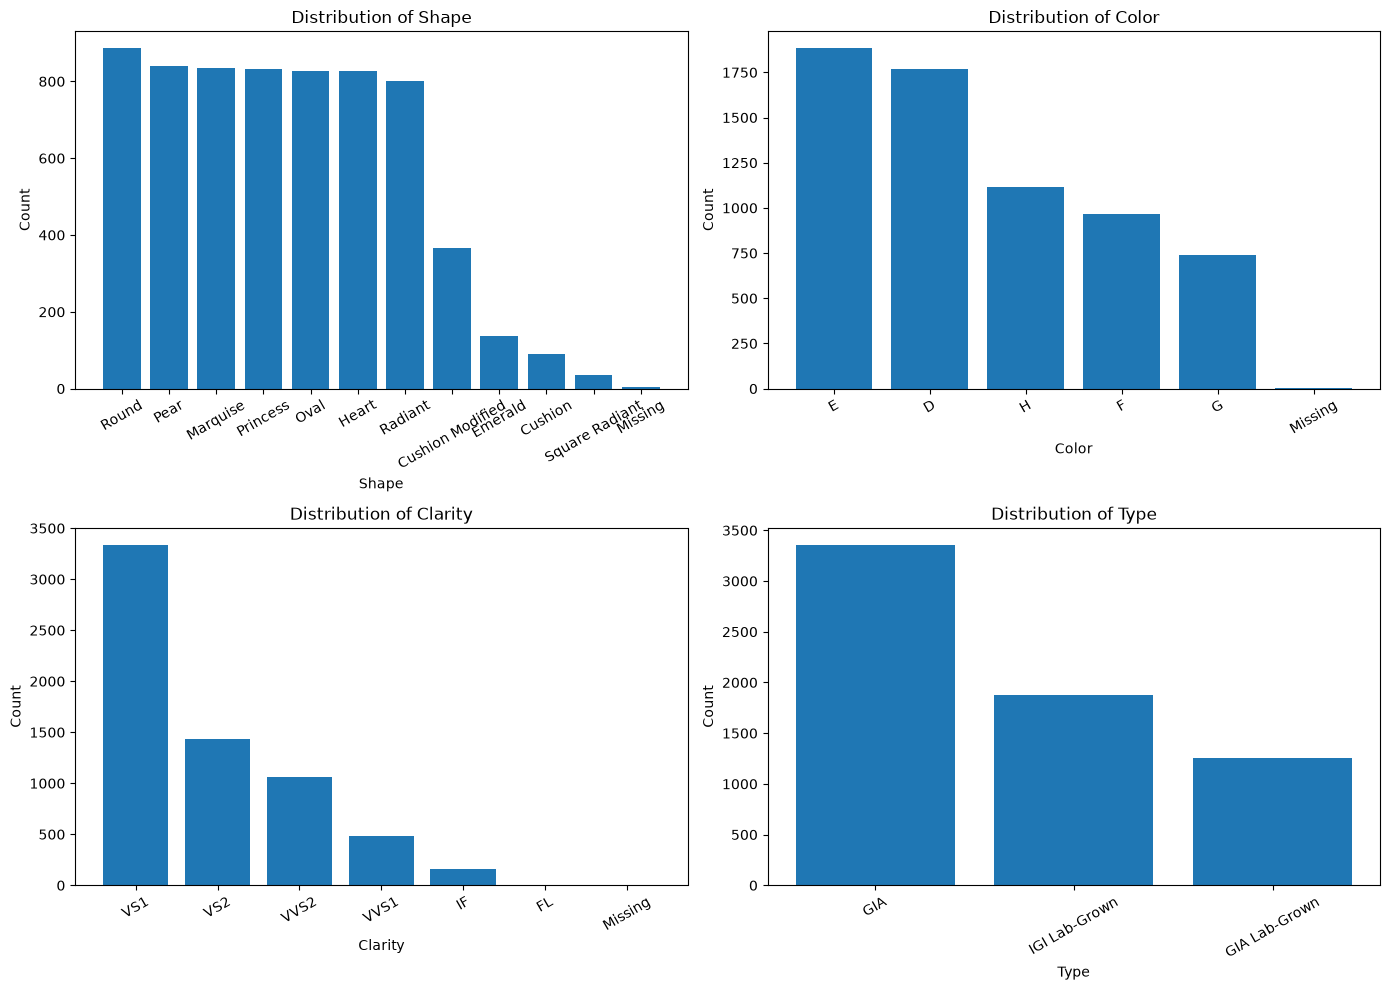

In [15]:
# Step 138: Important Categorical Feature Distributions

features_to_plot = [
    "Shape",
    "Color",
    "Clarity",
    "Type"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), features_to_plot):

    counts = df[feature].fillna("Missing").value_counts()

    labels = [str(x) for x in counts.index]
    values = counts.values

    ax.bar(labels, values)

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Exploratory Data Analysis Summary

The exploratory analysis revealed several important characteristics of the dataset.

- The price distribution is right-skewed, with most observations concentrated in the lower price range and a smaller number of high-price observations.
- Carat Weight shows an overall positive association with diamond price, although the relationship is not purely linear.
- Among numerical variables, Carat Weight has the highest correlation with Price (r = 0.3688), followed by Length (r = 0.3148) and Width (r = 0.2613).
- Several numerical features show strong inter-feature correlations, particularly Width and Height (r = 0.92), Length/Width Ratio and Length (r = 0.86), and Carat Weight with Height (r = 0.83).
- Diamond Type shows substantial differences in observed mean and median prices across the three groups.
- Categorical feature distributions are not uniform; for example, VS1 is the most frequent Clarity category and GIA is the largest Type group.
- Missingness is highly concentrated in Cut, Culet, and Fluorescence and is strongly associated with Diamond Type. These variables are therefore retained and handled using an explicit "Unknown" category during preprocessing.

These findings motivate the subsequent preprocessing, feature-ablation, model-comparison, validation, and explainability experiments.

## Data Preprocessing

Before model training, the dataset is divided into predictor variables and the target variable.

Categorical features are handled using missing-value replacement with an explicit `"Unknown"` category followed by one-hot encoding. Numerical features are handled using median imputation.

All preprocessing operations are fitted only on the training data through a preprocessing pipeline to avoid data leakage.

The dataset is split into training and testing subsets using an 80:20 ratio with a fixed random state of 42.

In [16]:
# Step 140: Train-Test Split

from sklearn.model_selection import train_test_split

X = df.drop("Price", axis=1)
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (5185, 17)
Testing features shape: (1297, 17)
Training target shape: (5185,)
Testing target shape: (1297,)


In [17]:
# Step 141: Define Feature Types

categorical_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Type",
    "Fluorescence"
]

numerical_features = [
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Length",
    "Width",
    "Height"
]

print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))
print("Total predictor features:", len(categorical_features) + len(numerical_features))

Number of categorical features: 10
Number of numerical features: 7
Total predictor features: 17


In [18]:
# Step 142: Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
# Step 143: Fit Preprocessor on Training Data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (5185, 88)
Testing processed shape: (1297, 88)


In [20]:
# Step 144: Processed Feature Names

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print("\nFirst 20 processed features:")
print(feature_names[:20])

Total processed features: 88

First 20 processed features:
['num__Carat Weight' 'num__Length/Width Ratio' 'num__Depth %'
 'num__Table %' 'num__Length' 'num__Width' 'num__Height'
 'cat__Shape_Cushion' 'cat__Shape_Cushion Modified' 'cat__Shape_Emerald'
 'cat__Shape_Heart' 'cat__Shape_Marquise' 'cat__Shape_Oval'
 'cat__Shape_Pear' 'cat__Shape_Princess' 'cat__Shape_Radiant'
 'cat__Shape_Round' 'cat__Shape_Square Radiant' 'cat__Shape_Unknown'
 'cat__Cut_Astor']


In [21]:
# Step 145: Verify Preprocessed Data

if hasattr(X_train_processed, "toarray"):
    X_train_check = X_train_processed.toarray()
else:
    X_train_check = X_train_processed

if hasattr(X_test_processed, "toarray"):
    X_test_check = X_test_processed.toarray()
else:
    X_test_check = X_test_processed

print("Missing values in processed training data:",
      np.isnan(X_train_check).sum())

print("Missing values in processed testing data:",
      np.isnan(X_test_check).sum())

print("Training processed shape:", X_train_check.shape)
print("Testing processed shape:", X_test_check.shape)

Missing values in processed training data: 0
Missing values in processed testing data: 0
Training processed shape: (5185, 88)
Testing processed shape: (1297, 88)


In [22]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
y_pred = rf_model.predict(X_test_processed)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 1297


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Results")
print("---------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Random Forest Results
---------------------
MAE : 391.1
RMSE: 1118.07
R²  : 0.8774


In [26]:
results = []

results.append({
    "Experiment": "Baseline - Random Forest",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.87744


In [27]:
four_c_features = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity"
]

X_train_4c = X_train[four_c_features]
X_test_4c = X_test[four_c_features]

print("4C features:")
print(four_c_features)

print("\nTraining shape:", X_train_4c.shape)
print("Testing shape :", X_test_4c.shape)

4C features:
['Carat Weight', 'Cut', 'Color', 'Clarity']

Training shape: (5185, 4)
Testing shape : (1297, 4)


In [28]:
four_c_categorical = [
    "Cut",
    "Color",
    "Clarity"
]

four_c_numerical = [
    "Carat Weight"
]

four_c_preprocessor = ColumnTransformer([
    ("num",
     SimpleImputer(strategy="median"),
     four_c_numerical),

    ("cat",
     Pipeline([
         ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     four_c_categorical)
])

print("4C preprocessing pipeline created successfully!")

4C preprocessing pipeline created successfully!


4C training preprocessing completed!
Original shape: (5185, 4)
Processed shape: (5185, 19)


In [30]:
X_test_4c_processed = four_c_preprocessor.transform(X_test_4c)

print("4C test preprocessing completed!")
print("Original shape:", X_test_4c.shape)
print("Processed shape:", X_test_4c_processed.shape)

4C test preprocessing completed!
Original shape: (1297, 4)
Processed shape: (1297, 19)


In [31]:
rf_4c = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_4c.fit(X_train_4c_processed, y_train)

print("4C Random Forest model trained successfully!")

4C Random Forest model trained successfully!


In [32]:
y_pred_4c = rf_4c.predict(X_test_4c_processed)

print("4C predictions generated successfully!")
print("Number of predictions:", len(y_pred_4c))



4C predictions generated successfully!
Number of predictions: 1297


In [33]:
mae_4c = mean_absolute_error(y_test, y_pred_4c)
rmse_4c = np.sqrt(mean_squared_error(y_test, y_pred_4c))
r2_4c = r2_score(y_test, y_pred_4c)

print("4C Random Forest Results")
print("------------------------")
print("MAE :", round(mae_4c, 2))
print("RMSE:", round(rmse_4c, 2))
print("R²  :", round(r2_4c, 4))

4C Random Forest Results
------------------------
MAE : 951.62
RMSE: 2315.88
R²  : 0.4742


In [34]:
results.append({
    "Experiment": "4C - Random Forest",
    "MAE": mae_4c,
    "RMSE": rmse_4c,
    "R2": r2_4c
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177


In [35]:
four_c_dimension_features = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity",
    "Length",
    "Width",
    "Height"
]

X_train_4c_dim = X_train[four_c_dimension_features]
X_test_4c_dim = X_test[four_c_dimension_features]

print("4C + Dimensions features:")
print(four_c_dimension_features)

print("\nTraining shape:", X_train_4c_dim.shape)
print("Testing shape :", X_test_4c_dim.shape)

4C + Dimensions features:
['Carat Weight', 'Cut', 'Color', 'Clarity', 'Length', 'Width', 'Height']

Training shape: (5185, 7)
Testing shape : (1297, 7)


In [36]:
four_c_dim_categorical = [
    "Cut",
    "Color",
    "Clarity"
]

four_c_dim_numerical = [
    "Carat Weight",
    "Length",
    "Width",
    "Height"
]

four_c_dim_preprocessor = ColumnTransformer([
    ("num",
     SimpleImputer(strategy="median"),
     four_c_dim_numerical),

    ("cat",
     Pipeline([
         ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     four_c_dim_categorical)
])

print("4C + Dimensions preprocessing pipeline created successfully!")

4C + Dimensions preprocessing pipeline created successfully!


In [37]:
X_train_4c_dim_processed = four_c_dim_preprocessor.fit_transform(X_train_4c_dim)

X_test_4c_dim_processed = four_c_dim_preprocessor.transform(X_test_4c_dim)

print("4C + Dimensions preprocessing completed!")
print("Training processed shape:", X_train_4c_dim_processed.shape)
print("Testing processed shape :", X_test_4c_dim_processed.shape)

4C + Dimensions preprocessing completed!
Training processed shape: (5185, 22)
Testing processed shape : (1297, 22)


In [38]:
rf_4c_dim = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_4c_dim.fit(X_train_4c_dim_processed, y_train)

print("4C + Dimensions Random Forest model trained successfully!")

4C + Dimensions Random Forest model trained successfully!


In [39]:
y_pred_4c_dim = rf_4c_dim.predict(X_test_4c_dim_processed)

print("4C + Dimensions predictions generated successfully!")
print("Number of predictions:", len(y_pred_4c_dim))

4C + Dimensions predictions generated successfully!
Number of predictions: 1297


In [40]:
mae_4c_dim = mean_absolute_error(y_test, y_pred_4c_dim)
rmse_4c_dim = np.sqrt(mean_squared_error(y_test, y_pred_4c_dim))
r2_4c_dim = r2_score(y_test, y_pred_4c_dim)

print("4C + Dimensions Random Forest Results")
print("--------------------------------------")
print("MAE :", round(mae_4c_dim, 2))
print("RMSE:", round(rmse_4c_dim, 2))
print("R²  :", round(r2_4c_dim, 4))

4C + Dimensions Random Forest Results
--------------------------------------
MAE : 595.42
RMSE: 1360.56
R²  : 0.8185


In [41]:
results.append({
    "Experiment": "4C + Dimensions - Random Forest",
    "MAE": mae_4c_dim,
    "RMSE": rmse_4c_dim,
    "R2": r2_4c_dim
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177
2,4C + Dimensions - Random Forest,595.417649,1360.557217,0.818514


In [42]:
physical_quality_features = [
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry"
]

four_c_dim_quality_features = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity",
    "Length",
    "Width",
    "Height",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry"
]

X_train_4c_dim_quality = X_train[four_c_dim_quality_features]
X_test_4c_dim_quality = X_test[four_c_dim_quality_features]

print("4C + Dimensions + Physical/Quality features:")
print(four_c_dim_quality_features)

print("\nTraining shape:", X_train_4c_dim_quality.shape)
print("Testing shape :", X_test_4c_dim_quality.shape)

4C + Dimensions + Physical/Quality features:
['Carat Weight', 'Cut', 'Color', 'Clarity', 'Length', 'Width', 'Height', 'Length/Width Ratio', 'Depth %', 'Table %', 'Polish', 'Symmetry']

Training shape: (5185, 12)
Testing shape : (1297, 12)


In [43]:
four_c_dim_quality_categorical = [
    "Cut",
    "Color",
    "Clarity",
    "Polish",
    "Symmetry"
]

four_c_dim_quality_numerical = [
    "Carat Weight",
    "Length",
    "Width",
    "Height",
    "Length/Width Ratio",
    "Depth %",
    "Table %"
]

four_c_dim_quality_preprocessor = ColumnTransformer([
    ("num",
     SimpleImputer(strategy="median"),
     four_c_dim_quality_numerical),

    ("cat",
     Pipeline([
         ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     four_c_dim_quality_categorical)
])

print("4C + Dimensions + Physical/Quality preprocessing pipeline created successfully!")

4C + Dimensions + Physical/Quality preprocessing pipeline created successfully!


In [44]:
X_train_4c_dim_quality_processed = (
    four_c_dim_quality_preprocessor.fit_transform(
        X_train_4c_dim_quality
    )
)

X_test_4c_dim_quality_processed = (
    four_c_dim_quality_preprocessor.transform(
        X_test_4c_dim_quality
    )
)

print("4C + Dimensions + Physical/Quality preprocessing completed!")
print(
    "Training processed shape:",
    X_train_4c_dim_quality_processed.shape
)
print(
    "Testing processed shape :",
    X_test_4c_dim_quality_processed.shape
)

4C + Dimensions + Physical/Quality preprocessing completed!
Training processed shape: (5185, 33)
Testing processed shape : (1297, 33)


In [45]:
rf_4c_dim_quality = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_4c_dim_quality.fit(
    X_train_4c_dim_quality_processed,
    y_train
)

print("4C + Dimensions + Physical/Quality Random Forest model trained successfully!")

4C + Dimensions + Physical/Quality Random Forest model trained successfully!


In [46]:
y_pred_4c_dim_quality = rf_4c_dim_quality.predict(
    X_test_4c_dim_quality_processed
)

print("4C + Dimensions + Physical/Quality predictions generated successfully!")
print("Number of predictions:", len(y_pred_4c_dim_quality))

4C + Dimensions + Physical/Quality predictions generated successfully!
Number of predictions: 1297


In [47]:
mae_4c_dim_quality = mean_absolute_error(
    y_test,
    y_pred_4c_dim_quality
)

rmse_4c_dim_quality = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_4c_dim_quality
    )
)

r2_4c_dim_quality = r2_score(
    y_test,
    y_pred_4c_dim_quality
)

print("4C + Dimensions + Physical/Quality Results")
print("-------------------------------------------")
print("MAE :", round(mae_4c_dim_quality, 2))
print("RMSE:", round(rmse_4c_dim_quality, 2))
print("R²  :", round(r2_4c_dim_quality, 4))

4C + Dimensions + Physical/Quality Results
-------------------------------------------
MAE : 577.23
RMSE: 1282.68
R²  : 0.8387


In [48]:
results.append({
    "Experiment": "4C + Dimensions + Physical/Quality - Random Forest",
    "MAE": mae_4c_dim_quality,
    "RMSE": rmse_4c_dim_quality,
    "R2": r2_4c_dim_quality
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177
2,4C + Dimensions - Random Forest,595.417649,1360.557217,0.818514
3,4C + Dimensions + Physical/Quality - Random Fo...,577.229997,1282.675992,0.838697


In [49]:
all_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Length",
    "Width",
    "Height",
    "Type",
    "Fluorescence"
]

X_train_all = X_train[all_features]
X_test_all = X_test[all_features]

print("All selected features:")
print(all_features)

print("\nTraining shape:", X_train_all.shape)
print("Testing shape :", X_test_all.shape)

All selected features:
['Shape', 'Cut', 'Color', 'Clarity', 'Carat Weight', 'Length/Width Ratio', 'Depth %', 'Table %', 'Polish', 'Symmetry', 'Girdle', 'Culet', 'Length', 'Width', 'Height', 'Type', 'Fluorescence']

Training shape: (5185, 17)
Testing shape : (1297, 17)


In [50]:
all_categorical = X_train_all.select_dtypes(
    include=["object"]
).columns.tolist()

all_numerical = X_train_all.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

all_preprocessor = ColumnTransformer([
    ("num",
     SimpleImputer(strategy="median"),
     all_numerical),

    ("cat",
     Pipeline([
         ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     all_categorical)
])

print("All-feature preprocessing pipeline created successfully!")

print("\nCategorical features:", all_categorical)
print("Numerical features:", all_numerical)

All-feature preprocessing pipeline created successfully!

Categorical features: ['Shape', 'Cut', 'Color', 'Clarity', 'Polish', 'Symmetry', 'Girdle', 'Culet', 'Type', 'Fluorescence']
Numerical features: ['Carat Weight', 'Length/Width Ratio', 'Depth %', 'Table %', 'Length', 'Width', 'Height']


C:\Users\ishan\AppData\Local\Temp\ipykernel_9644\2333776696.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  all_categorical = X_train_all.select_dtypes(


In [51]:
X_train_all_processed = all_preprocessor.fit_transform(X_train_all)

X_test_all_processed = all_preprocessor.transform(X_test_all)

print("All-feature preprocessing completed!")
print("Training processed shape:", X_train_all_processed.shape)
print("Testing processed shape :", X_test_all_processed.shape)

All-feature preprocessing completed!
Training processed shape: (5185, 88)
Testing processed shape : (1297, 88)


In [52]:
rf_all = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_all.fit(
    X_train_all_processed,
    y_train
)

print("All-feature Random Forest model trained successfully!")

All-feature Random Forest model trained successfully!


In [53]:
y_pred_all = rf_all.predict(X_test_all_processed)

print("All-feature predictions generated successfully!")
print("Number of predictions:", len(y_pred_all))

All-feature predictions generated successfully!
Number of predictions: 1297


In [54]:
mae_all = mean_absolute_error(y_test, y_pred_all)

rmse_all = np.sqrt(
    mean_squared_error(y_test, y_pred_all)
)

r2_all = r2_score(y_test, y_pred_all)

print("All-Feature Random Forest Results")
print("---------------------------------")
print("MAE :", round(mae_all, 2))
print("RMSE:", round(rmse_all, 2))
print("R²  :", round(r2_all, 4))

All-Feature Random Forest Results
---------------------------------
MAE : 391.1
RMSE: 1118.07
R²  : 0.8774


In [55]:
results.append({
    "Experiment": "All 17 Features - Random Forest",
    "MAE": mae_all,
    "RMSE": rmse_all,
    "R2": r2_all
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177
2,4C + Dimensions - Random Forest,595.417649,1360.557217,0.818514
3,4C + Dimensions + Physical/Quality - Random Fo...,577.229997,1282.675992,0.838697
4,All 17 Features - Random Forest,391.103845,1118.074804,0.877440


In [56]:
from sklearn.ensemble import ExtraTreesRegressor

extra_trees = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

extra_trees.fit(
    X_train_all_processed,
    y_train
)

print("Extra Trees model trained successfully!")

Extra Trees model trained successfully!


In [57]:
y_pred_extra = extra_trees.predict(X_test_all_processed)

print("Extra Trees predictions generated successfully!")
print("Number of predictions:", len(y_pred_extra))

Extra Trees predictions generated successfully!
Number of predictions: 1297


In [58]:
mae_extra = mean_absolute_error(y_test, y_pred_extra)
rmse_extra = np.sqrt(mean_squared_error(y_test, y_pred_extra))
r2_extra = r2_score(y_test, y_pred_extra)

print("Extra Trees Results")
print("-------------------")
print("MAE :", round(mae_extra, 2))
print("RMSE:", round(rmse_extra, 2))
print("R²  :", round(r2_extra, 4))

Extra Trees Results
-------------------
MAE : 405.63
RMSE: 1242.79
R²  : 0.8486


In [59]:
results.append({
    "Experiment": "Extra Trees - All 17 Features",
    "MAE": mae_extra,
    "RMSE": rmse_extra,
    "R2": r2_extra
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177
2,4C + Dimensions - Random Forest,595.417649,1360.557217,0.818514
3,4C + Dimensions + Physical/Quality - Random Fo...,577.229997,1282.675992,0.838697
4,All 17 Features - Random Forest,391.103845,1118.074804,0.877440
5,Extra Trees - All 17 Features,405.625998,1242.791826,0.848572


In [60]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gbr_model.fit(
    X_train_all_processed,
    y_train
)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [61]:
y_pred_gbr = gbr_model.predict(X_test_all_processed)

print("Gradient Boosting predictions generated successfully!")
print("Number of predictions:", len(y_pred_gbr))

Gradient Boosting predictions generated successfully!
Number of predictions: 1297


In [62]:
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)

rmse_gbr = np.sqrt(
    mean_squared_error(y_test, y_pred_gbr)
)

r2_gbr = r2_score(
    y_test,
    y_pred_gbr
)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE :", round(mae_gbr, 2))
print("RMSE:", round(rmse_gbr, 2))
print("R²  :", round(r2_gbr, 4))

Gradient Boosting Results
-------------------------
MAE : 458.34
RMSE: 1159.06
R²  : 0.8683


In [63]:
results.append({
    "Experiment": "Gradient Boosting - All 17 Features",
    "MAE": mae_gbr,
    "RMSE": rmse_gbr,
    "R2": r2_gbr
})

results_df = pd.DataFrame(results)

results_df

,Experiment,MAE,RMSE,R2
0,Baseline - Random Forest,391.103845,1118.074804,0.877440
1,4C - Random Forest,951.624187,2315.877319,0.474177
2,4C + Dimensions - Random Forest,595.417649,1360.557217,0.818514
3,4C + Dimensions + Physical/Quality - Random Fo...,577.229997,1282.675992,0.838697
4,All 17 Features - Random Forest,391.103845,1118.074804,0.877440
5,Extra Trees - All 17 Features,405.625998,1242.791826,0.848572
6,Gradient Boosting - All 17 Features,458.341882,1159.055321,0.868291


In [64]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross-Validation setup completed!")

5-Fold Cross-Validation setup completed!


In [65]:
cv_results = cross_validate(
    rf_all,
    X_train_all_processed,
    y_train,
    cv=kf,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

cv_mae = -cv_results["test_MAE"]
cv_rmse = -cv_results["test_RMSE"]
cv_r2 = cv_results["test_R2"]

print("5-Fold Cross-Validation Results")
print("--------------------------------")
print("MAE scores :", np.round(cv_mae, 2))
print("RMSE scores:", np.round(cv_rmse, 2))
print("R² scores  :", np.round(cv_r2, 4))

print("\nMean MAE :", round(cv_mae.mean(), 2))
print("Mean RMSE:", round(cv_rmse.mean(), 2))
print("Mean R²  :", round(cv_r2.mean(), 4))

print("\nStd MAE :", round(cv_mae.std(), 2))
print("Std RMSE:", round(cv_rmse.std(), 2))
print("Std R²  :", round(cv_r2.std(), 4))

5-Fold Cross-Validation Results
--------------------------------
MAE scores : [471.59 420.17 431.54 373.11 520.57]
RMSE scores: [1406.43 1164.59 1508.24  987.52 1694.07]
R² scores  : [0.8339 0.8997 0.7283 0.9002 0.7354]

Mean MAE : 443.4
Mean RMSE: 1352.17
Mean R²  : 0.8195

Std MAE : 49.74
Std RMSE: 249.94
Std R²  : 0.0756


In [66]:
cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Mean": [
        cv_mae.mean(),
        cv_rmse.mean(),
        cv_r2.mean()
    ],
    "Std": [
        cv_mae.std(),
        cv_rmse.std(),
        cv_r2.std()
    ]
})

cv_summary

,Metric,Mean,Std
0,MAE,443.397097,49.741331
1,RMSE,1352.169178,249.942622
2,R2,0.819502,0.075560


In [67]:
try:
    import shap
    print("SHAP is already installed!")
    print("SHAP version:", shap.__version__)
except ImportError:
    print("SHAP is not installed.")

SHAP is already installed!
SHAP version: 0.52.0


In [68]:
import shap

print("SHAP imported successfully!")
print("SHAP version:", shap.__version__)

SHAP imported successfully!
SHAP version: 0.52.0


In [69]:
explainer = shap.TreeExplainer(rf_all)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [70]:
X_test_sample = X_test_all_processed[:200]

if hasattr(X_test_sample, "toarray"):
    X_test_sample = X_test_sample.toarray()

X_test_sample = np.asarray(X_test_sample, dtype=np.float64)

print("Sample prepared successfully!")
print("Sample shape:", X_test_sample.shape)
print("Data type:", X_test_sample.dtype)

Sample prepared successfully!
Sample shape: (200, 88)
Data type: float64


In [71]:
shap_values = explainer.shap_values(X_test_sample)

print("SHAP values calculated successfully!")
print("SHAP shape:", np.array(shap_values).shape)

SHAP values calculated successfully!
SHAP shape: (200, 88)


In [72]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    "Feature_Index": range(len(mean_abs_shap)),
    "Mean_Abs_SHAP": mean_abs_shap
})

feature_importance = feature_importance.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

feature_importance.head(15)

,Feature_Index,Mean_Abs_SHAP
81,81,1517.823592
0,0,789.503944
4,4,373.409162
5,5,225.939150
11,11,181.007498
24,24,105.945877
28,28,100.002372
2,2,87.157289
34,34,77.617395
33,33,48.418506


In [73]:
feature_names = all_preprocessor.get_feature_names_out()

feature_importance["Feature"] = feature_names[
    feature_importance["Feature_Index"]
]

feature_importance = feature_importance[
    ["Feature", "Mean_Abs_SHAP"]
]

feature_importance.head(15)

,Feature,Mean_Abs_SHAP
81,cat__Type_GIA,1517.823592
0,num__Carat Weight,789.503944
4,num__Length,373.409162
5,num__Width,225.939150
11,cat__Shape_Marquise,181.007498
24,cat__Color_D,105.945877
28,cat__Color_H,100.002372
2,num__Depth %,87.157289
34,cat__Clarity_VS2,77.617395
33,cat__Clarity_VS1,48.418506


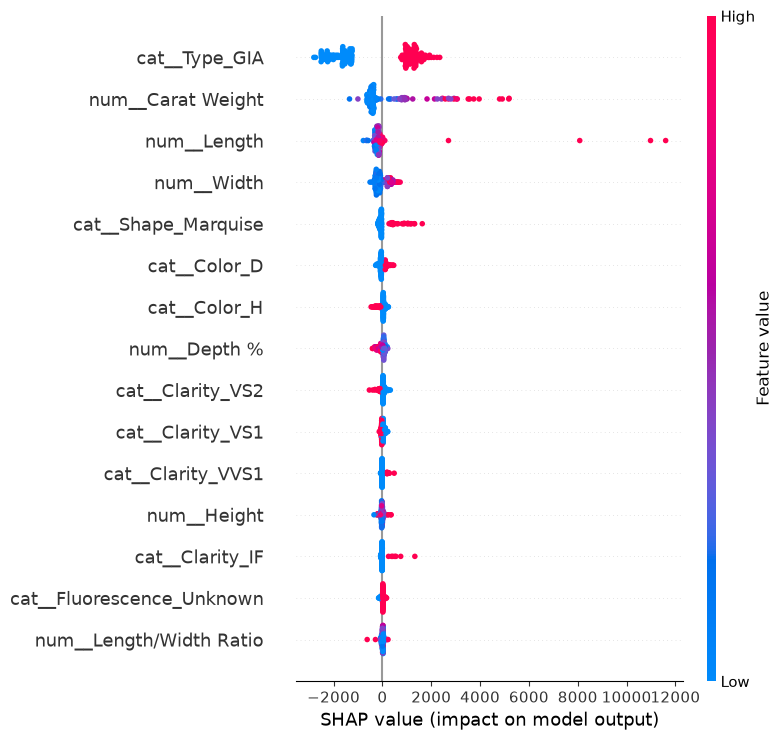

In [74]:
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names,
    max_display=15
)

In [75]:
sample_index = 0

sample_diamond = X_test_all.iloc[[sample_index]]

print("Selected diamond:")
print(sample_diamond.T)

Selected diamond:
                                   3558
Shape                              Pear
Cut                                 NaN
Color                                 D
Clarity                             VS2
Carat Weight                       1.01
Length/Width Ratio                 1.53
Depth %                            64.2
Table %                            56.0
Polish                        Excellent
Symmetry                      Excellent
Girdle              Thick to Very Thick
Culet                               NaN
Length                             8.36
Width                              5.48
Height                             3.52
Type                                GIA
Fluorescence                        NaN


In [76]:
original_prediction = rf_all.predict(
    X_test_all_processed[[0]]
)[0]

actual_price = y_test.iloc[0]

print("Original predicted price:", round(original_prediction, 2))
print("Actual price:", actual_price)
print("Prediction error:", round(abs(actual_price - original_prediction), 2))

Original predicted price: 4601.44
Actual price: 4390
Prediction error: 211.44


In [77]:
what_if_diamond = X_test_all.iloc[[0]].copy()

what_if_diamond["Carat Weight"] = 1.50

what_if_processed = all_preprocessor.transform(
    what_if_diamond
)

what_if_prediction = rf_all.predict(
    what_if_processed
)[0]

print("Original Carat Weight:", X_test_all.iloc[0]["Carat Weight"])
print("What-If Carat Weight:", what_if_diamond.iloc[0]["Carat Weight"])

print("\nOriginal prediction:", round(original_prediction, 2))
print("What-If prediction :", round(what_if_prediction, 2))
print(
    "Price difference    :",
    round(what_if_prediction - original_prediction, 2)
)

Original Carat Weight: 1.01
What-If Carat Weight: 1.5

Original prediction: 4601.44
What-If prediction : 9299.76
Price difference    : 4698.32


In [78]:
what_if_color = X_test_all.iloc[[0]].copy()

what_if_color["Color"] = "H"

what_if_color_processed = all_preprocessor.transform(
    what_if_color
)

what_if_color_prediction = rf_all.predict(
    what_if_color_processed
)[0]

print("Original Color:", X_test_all.iloc[0]["Color"])
print("What-If Color :", what_if_color.iloc[0]["Color"])

print("\nOriginal prediction:", round(original_prediction, 2))
print("What-If prediction :", round(what_if_color_prediction, 2))
print(
    "Price difference    :",
    round(what_if_color_prediction - original_prediction, 2)
)

Original Color: D
What-If Color : H

Original prediction: 4601.44
What-If prediction : 3685.1
Price difference    : -916.34


In [79]:
what_if_results = pd.DataFrame([
    {
        "Scenario": "Original",
        "Changed Feature": "None",
        "Original Value": "Carat 1.01, Color D",
        "New Value": "Carat 1.01, Color D",
        "Predicted Price": original_prediction
    },
    {
        "Scenario": "Carat What-If",
        "Changed Feature": "Carat Weight",
        "Original Value": 1.01,
        "New Value": 1.50,
        "Predicted Price": what_if_prediction
    },
    {
        "Scenario": "Color What-If",
        "Changed Feature": "Color",
        "Original Value": "D",
        "New Value": "H",
        "Predicted Price": what_if_color_prediction
    }
])

what_if_results

,Scenario,Changed Feature,Original Value,New Value,Predicted Price
0,Original,None,"Carat 1.01, Color D","Carat 1.01, Color D",4601.44
1,Carat What-If,Carat Weight,1.01,1.5,9299.76
2,Color What-If,Color,D,H,3685.10


In [80]:
# Step 106: Final Results Summary

final_results = pd.DataFrame({
    "Experiment": [
        "4C Features",
        "4C + Dimensions",
        "4C + Dimensions + Physical/Quality",
        "All 17 Features - Random Forest",
        "All 17 Features - Gradient Boosting",
        "All 17 Features - Extra Trees"
    ],
    "MAE": [
        951.624187,
        595.417649,
        577.229997,
        391.103845,
        458.341882,
        405.625998
    ],
    "RMSE": [
        2315.877319,
        1360.557217,
        1282.675992,
        1118.074804,
        1159.055321,
        1242.791826
    ],
    "R2": [
        0.474177,
        0.818514,
        0.838697,
        0.877440,
        0.868291,
        0.848572
    ]
})

final_results

,Experiment,MAE,RMSE,R2
0,4C Features,951.624187,2315.877319,0.474177
1,4C + Dimensions,595.417649,1360.557217,0.818514
2,4C + Dimensions + Physical/Quality,577.229997,1282.675992,0.838697
3,All 17 Features - Random Forest,391.103845,1118.074804,0.877440
4,All 17 Features - Gradient Boosting,458.341882,1159.055321,0.868291
5,All 17 Features - Extra Trees,405.625998,1242.791826,0.848572


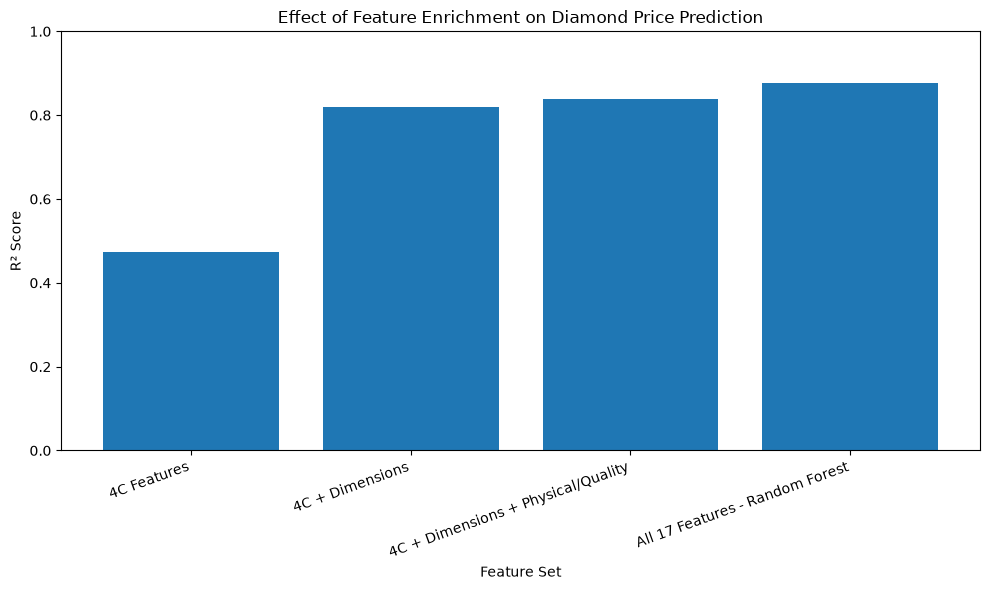

In [81]:
# Step 107: Feature Ablation - R² Comparison

import matplotlib.pyplot as plt

ablation_results = final_results.iloc[:4].copy()

plt.figure(figsize=(10, 6))

plt.bar(
    ablation_results["Experiment"],
    ablation_results["R2"]
)

plt.xlabel("Feature Set")
plt.ylabel("R² Score")
plt.title("Effect of Feature Enrichment on Diamond Price Prediction")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()

plt.show()

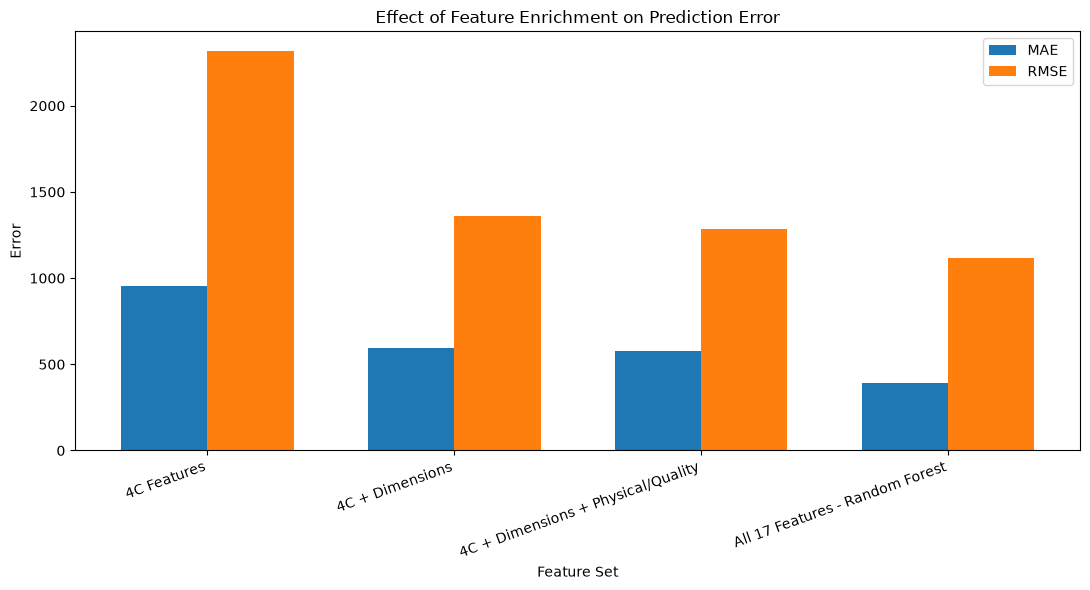

In [82]:
# Step 108: Feature Ablation - MAE and RMSE Comparison

import numpy as np
import matplotlib.pyplot as plt

ablation_results = final_results.iloc[:4].copy()

x = np.arange(len(ablation_results))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    ablation_results["MAE"],
    width,
    label="MAE"
)

plt.bar(
    x + width/2,
    ablation_results["RMSE"],
    width,
    label="RMSE"
)

plt.xlabel("Feature Set")
plt.ylabel("Error")
plt.title("Effect of Feature Enrichment on Prediction Error")

plt.xticks(
    x,
    ablation_results["Experiment"],
    rotation=20,
    ha="right"
)

plt.legend()
plt.tight_layout()

plt.show()

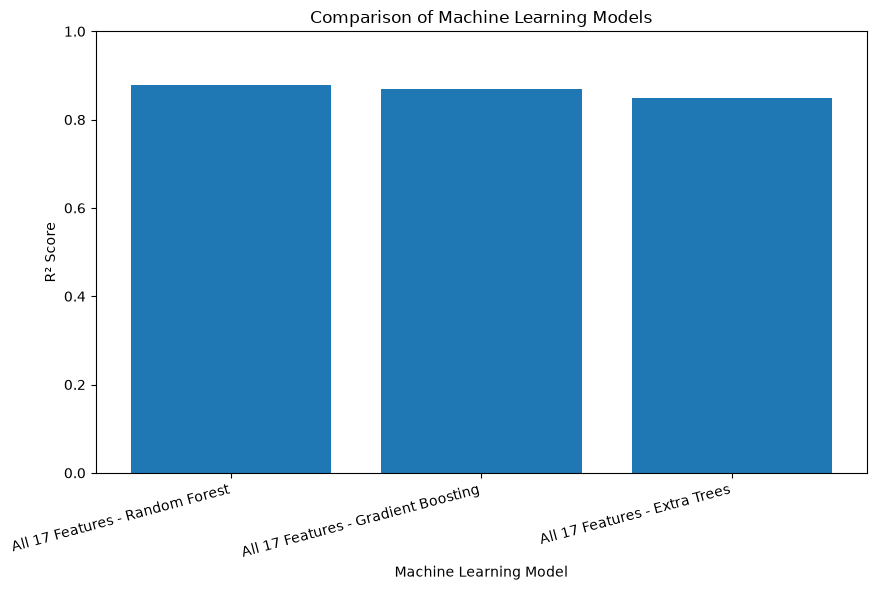

In [83]:
# Step 109: Model Comparison - R²

model_results = final_results.iloc[3:6].copy()

plt.figure(figsize=(9, 6))

plt.bar(
    model_results["Experiment"],
    model_results["R2"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.title("Comparison of Machine Learning Models")

plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.show()

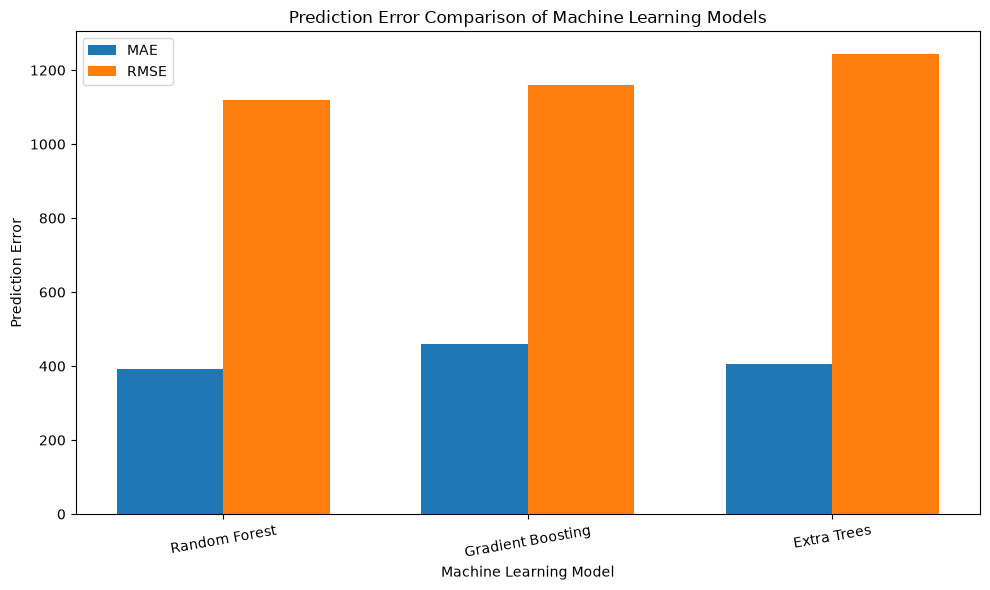

In [84]:
# Step 110: Model Comparison - MAE and RMSE

model_results = final_results.iloc[3:6].copy()

x = np.arange(len(model_results))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    model_results["MAE"],
    width,
    label="MAE"
)

plt.bar(
    x + width/2,
    model_results["RMSE"],
    width,
    label="RMSE"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error")
plt.title("Prediction Error Comparison of Machine Learning Models")

plt.xticks(
    x,
    ["Random Forest", "Gradient Boosting", "Extra Trees"],
    rotation=10
)

plt.legend()
plt.tight_layout()

plt.show()

In [85]:
# Step 111: Cross-Validation Summary

cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Mean": [
        443.397097,
        1352.169178,
        0.819502
    ],
    "Std": [
        49.741331,
        249.942622,
        0.075560
    ]
})

cv_summary

,Metric,Mean,Std
0,MAE,443.397097,49.741331
1,RMSE,1352.169178,249.942622
2,R²,0.819502,0.075560


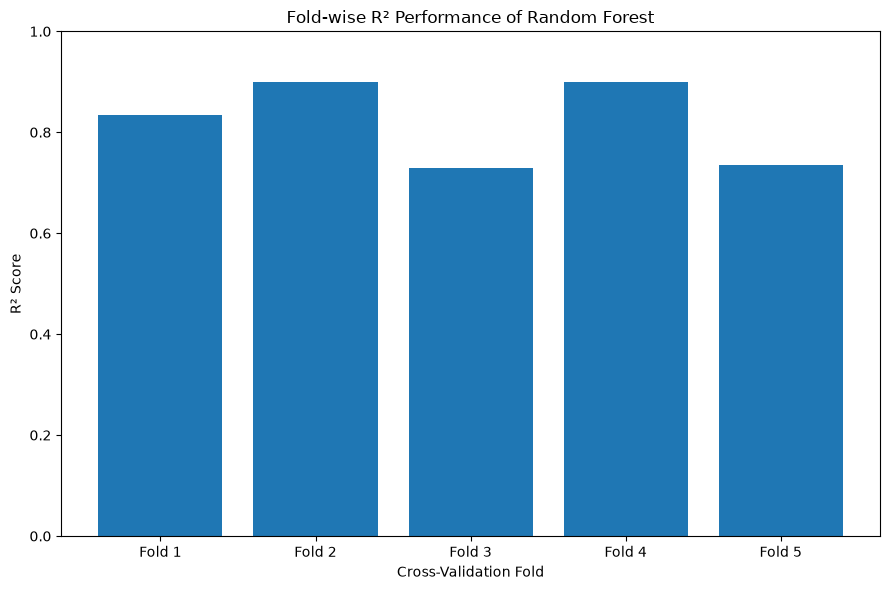

In [86]:
# Step 112: Cross-Validation Fold-wise R²

cv_r2 = np.array([
    0.8339,
    0.8997,
    0.7283,
    0.9002,
    0.7354
])

folds = [f"Fold {i}" for i in range(1, 6)]

plt.figure(figsize=(9, 6))

plt.bar(folds, cv_r2)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Fold-wise R² Performance of Random Forest")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

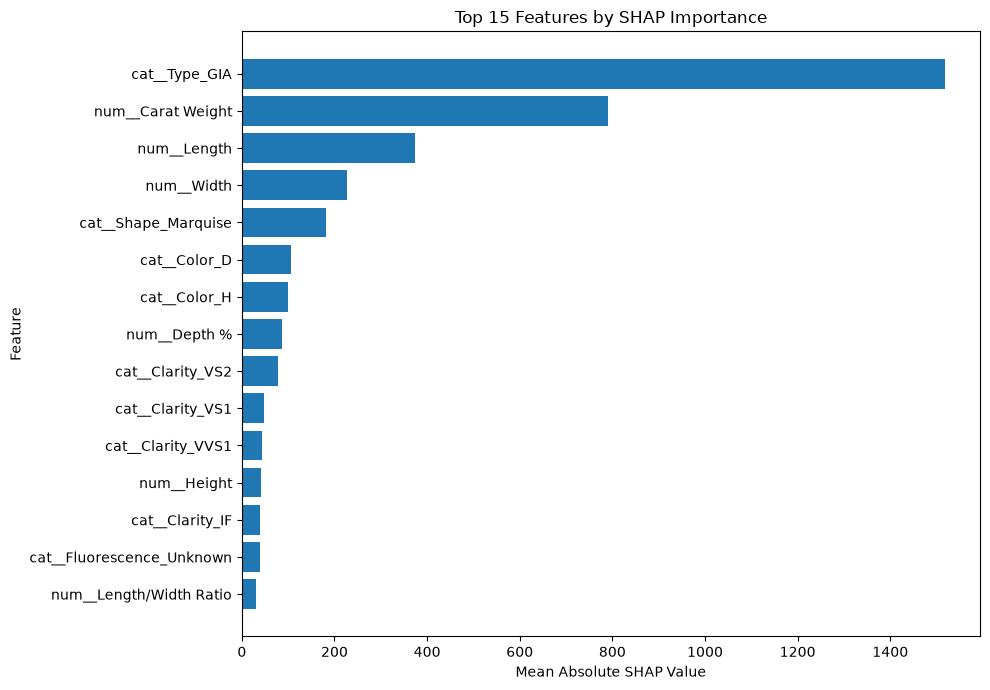

In [87]:
# Step 113: SHAP Feature Importance

shap_importance = np.abs(shap_values).mean(axis=0)

shap_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP": shap_importance
})

shap_df = shap_df.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).head(15)

shap_df = shap_df.sort_values(
    "Mean_Abs_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    shap_df["Feature"],
    shap_df["Mean_Abs_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 Features by SHAP Importance")

plt.tight_layout()
plt.show()

In [88]:
# Step 114: What-If Analysis

what_if_results = pd.DataFrame({
    "Scenario": [
        "Original",
        "Carat What-If",
        "Color What-If"
    ],
    "Changed Feature": [
        "None",
        "Carat Weight",
        "Color"
    ],
    "Original Value": [
        "1.01",
        "1.01",
        "D"
    ],
    "New Value": [
        "Same",
        "1.50",
        "H"
    ],
    "Predicted Price": [
        4601.44,
        9299.76,
        3685.10
    ]
})

what_if_results

,Scenario,Changed Feature,Original Value,New Value,Predicted Price
0,Original,None,1.01,Same,4601.44
1,Carat What-If,Carat Weight,1.01,1.50,9299.76
2,Color What-If,Color,D,H,3685.10


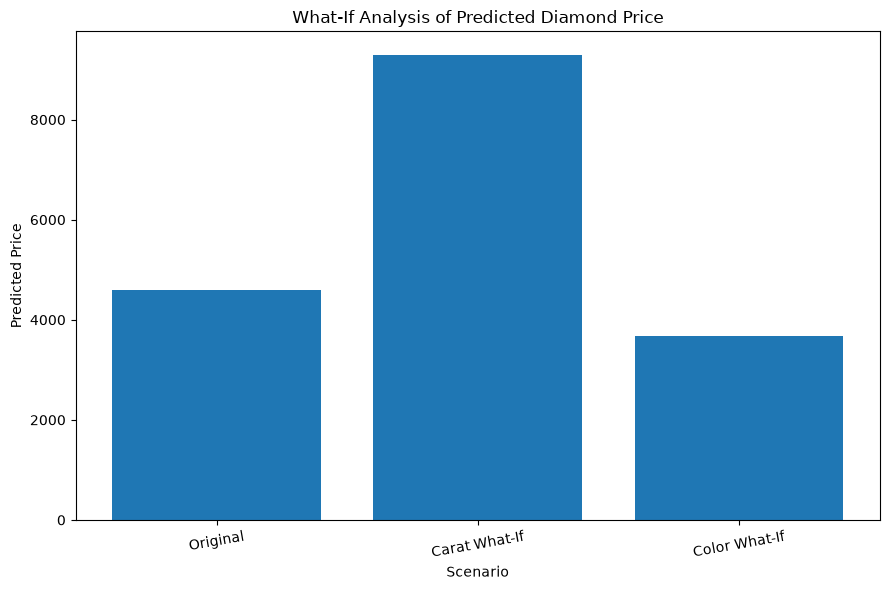

In [89]:
# Step 115: What-If Price Comparison

plt.figure(figsize=(9, 6))

plt.bar(
    what_if_results["Scenario"],
    what_if_results["Predicted Price"]
)

plt.xlabel("Scenario")
plt.ylabel("Predicted Price")
plt.title("What-If Analysis of Predicted Diamond Price")

plt.xticks(rotation=10)
plt.tight_layout()

plt.show()

In [90]:
# Step 116: Final Master Results Table

master_results = pd.DataFrame({
    "Experiment": [
        "4C Features",
        "4C + Dimensions",
        "4C + Dimensions + Physical/Quality",
        "All 17 Features - Random Forest",
        "All 17 Features - Gradient Boosting",
        "All 17 Features - Extra Trees"
    ],
    "MAE": [
        951.624187,
        595.417649,
        577.229997,
        391.103845,
        458.341882,
        405.625998
    ],
    "RMSE": [
        2315.877319,
        1360.557217,
        1282.675992,
        1118.074804,
        1159.055321,
        1242.791826
    ],
    "R2": [
        0.474177,
        0.818514,
        0.838697,
        0.877440,
        0.868291,
        0.848572
    ]
})

master_results

,Experiment,MAE,RMSE,R2
0,4C Features,951.624187,2315.877319,0.474177
1,4C + Dimensions,595.417649,1360.557217,0.818514
2,4C + Dimensions + Physical/Quality,577.229997,1282.675992,0.838697
3,All 17 Features - Random Forest,391.103845,1118.074804,0.877440
4,All 17 Features - Gradient Boosting,458.341882,1159.055321,0.868291
5,All 17 Features - Extra Trees,405.625998,1242.791826,0.848572


In [91]:
# Step 117: Final Research Findings

research_findings = pd.DataFrame({
    "Research Aspect": [
        "4C-only features",
        "Adding dimensions",
        "Adding physical/quality features",
        "Using all 17 features",
        "Model comparison",
        "Robust validation",
        "SHAP explainability",
        "What-If analysis"
    ],
    "Finding": [
        "4C features alone produced R² = 0.4742.",
        "Adding Length, Width and Height improved R² to 0.8185.",
        "Adding additional physical/quality features increased R² to 0.8387.",
        "The all-feature Random Forest achieved MAE = 391.10, RMSE = 1118.07 and R² = 0.8774 on the held-out test set.",
        "Random Forest, Gradient Boosting and Extra Trees showed different performance across MAE, RMSE and R².",
        "5-fold cross-validation produced mean R² = 0.8195 with std = 0.0756.",
        "SHAP identified Type_GIA, Carat Weight, Length and Width among the major model-contribution features.",
        "Controlled changes in Carat Weight and Color produced different model-based price estimates."
    ]
})

research_findings

,Research Aspect,Finding
0,4C-only features,4C features alone produced R² = 0.4742.
1,Adding dimensions,"Adding Length, Width and Height improved R² to..."
2,Adding physical/quality features,Adding additional physical/quality features in...
3,Using all 17 features,The all-feature Random Forest achieved MAE = 3...
4,Model comparison,"Random Forest, Gradient Boosting and Extra Tre..."
5,Robust validation,5-fold cross-validation produced mean R² = 0.8...
6,SHAP explainability,"SHAP identified Type_GIA, Carat Weight, Length..."
7,What-If analysis,Controlled changes in Carat Weight and Color p...


In [92]:
# Step 118: Limitations and Future Work

limitations_future_work = pd.DataFrame({
    "Category": [
        "Dataset",
        "Missing Data",
        "Generalization",
        "Model Scope",
        "Temporal Information",
        "Explainability",
        "Future Validation"
    ],
    "Limitation / Future Direction": [
        "The study uses a 6,485-row marketplace dataset, so results may not generalize to all diamond markets or retailers.",
        "Several categorical variables contain substantial missing values, particularly Fluorescence, Culet and Cut.",
        "The evaluation uses a random train-test split and K-fold validation; external datasets were not used for independent validation.",
        "The current study evaluates Random Forest, Gradient Boosting and Extra Trees rather than a larger range of advanced models.",
        "The dataset does not provide sufficient time-stamped transaction information for a true temporal price-trend study.",
        "SHAP explains model contribution but does not establish causal relationships.",
        "Future work can evaluate the framework on independent datasets, richer market sources and additional diamond characteristics."
    ]
})

limitations_future_work

,Category,Limitation / Future Direction
0,Dataset,"The study uses a 6,485-row marketplace dataset..."
1,Missing Data,Several categorical variables contain substant...
2,Generalization,The evaluation uses a random train-test split ...
3,Model Scope,"The current study evaluates Random Forest, Gra..."
4,Temporal Information,The dataset does not provide sufficient time-s...
5,Explainability,SHAP explains model contribution but does not ...
6,Future Validation,Future work can evaluate the framework on inde...


In [93]:
# Step 119: Final Research Conclusion

conclusion = pd.DataFrame({
    "Point": [
        "Research Objective",
        "Feature Contribution",
        "Prediction Performance",
        "Validation",
        "Explainability",
        "Practical Analysis",
        "Overall Conclusion"
    ],
    "Conclusion": [
        "The study evaluates whether richer diamond characteristics can improve machine-learning-based price prediction.",
        "Feature ablation shows that dimensions and additional physical/quality characteristics provide substantial improvements over 4C-only inputs.",
        "The all-feature Random Forest achieved MAE = 391.10, RMSE = 1118.07 and R² = 0.8774 on the held-out test set.",
        "Five-fold cross-validation gave mean R² = 0.8195 with a standard deviation of 0.0756, showing noticeable fold-to-fold variation.",
        "SHAP analysis provides feature-level explanations for the model predictions.",
        "What-If analysis allows controlled hypothetical changes in selected attributes to examine changes in model-predicted price.",
        "The proposed framework combines prediction, controlled feature analysis, validation and explainability rather than relying only on a single prediction model."
    ]
})

conclusion

,Point,Conclusion
0,Research Objective,The study evaluates whether richer diamond cha...
1,Feature Contribution,Feature ablation shows that dimensions and add...
2,Prediction Performance,The all-feature Random Forest achieved MAE = 3...
3,Validation,Five-fold cross-validation gave mean R² = 0.81...
4,Explainability,SHAP analysis provides feature-level explanati...
5,Practical Analysis,What-If analysis allows controlled hypothetica...
6,Overall Conclusion,"The proposed framework combines prediction, co..."
